## 1. Environment Setup

In [ ]:
# Check GPU
!nvidia-smi

Sat Aug 22 11:38:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -q timm grad-cam kaggle torchmetrics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 18.9 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision.transforms as T
from torchvision.datasets import ImageFolder
import timm
import numpy as np
import cv2
import os
import json
from pathlib import Path
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/plant_leaf_project'
os.makedirs(SAVE_DIR, exist_ok=True)
print("Artifacts will be saved to:", SAVE_DIR)

Mounted at /content/drive
Artifacts will be saved to: /content/drive/MyDrive/plant_leaf_project


## 3. Dataset Download

In [ ]:
# --- Option A: Download PlantVillage via Kaggle ---
from google.colab import files
print("Upload your kaggle.json (from https://www.kaggle.com/settings/account)")
uploaded = files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d abdallahalidev/plantvillage-dataset -p /content/data --unzip


Upload your kaggle.json (from https://www.kaggle.com/settings/account)


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:18<00:00, 117MB/s]



In [ ]:
# --- Option B: Download PlantDoc (field-condition images) — only needed later, for Phase 8 robustness testing ---
!git clone -q https://github.com/pratikkayal/PlantDoc-Dataset.git /content/plantdoc
print("PlantDoc cloned to /content/plantdoc")


PlantDoc cloned to /content/plantdoc


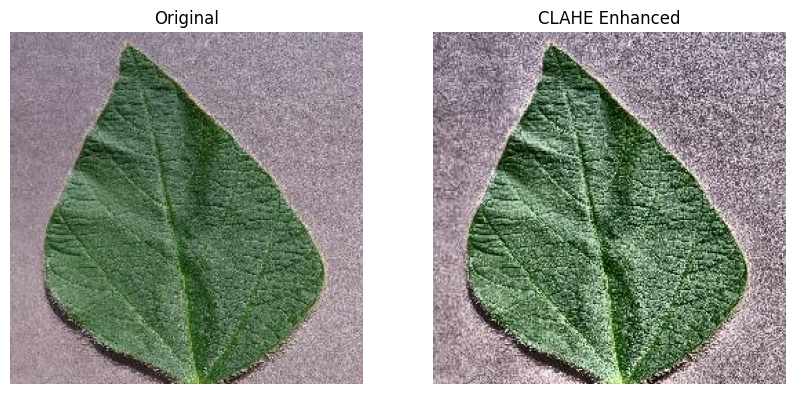

In [ ]:
DATA_ROOT = "/content/data/plantvillage dataset/color"

def apply_clahe(img):
    """img: PIL Image -> CLAHE-enhanced PIL Image (applied on the L channel in LAB space)"""
    img_np = np.array(img)
    lab = cv2.cvtColor(img_np, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_enhanced = clahe.apply(l)
    lab_enhanced = cv2.merge((l_enhanced, a, b))
    result = cv2.cvtColor(lab_enhanced, cv2.COLOR_LAB2RGB)
    return result

class CLAHETransform:
    def __call__(self, img):
        enhanced = apply_clahe(img)
        return T.functional.to_pil_image(enhanced)

# Quick visual check
from PIL import Image
sample_path = None
for root, dirs, files_ in os.walk(DATA_ROOT):
    for f in files_:
        if f.lower().endswith((".jpg", ".png", ".jpeg")):
            sample_path = os.path.join(root, f)
            break
    if sample_path:
        break

if sample_path:
    orig = Image.open(sample_path).convert("RGB")
    enhanced = CLAHETransform()(orig)
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(orig); ax[0].set_title("Original"); ax[0].axis("off")
    ax[1].imshow(enhanced); ax[1].set_title("CLAHE Enhanced"); ax[1].axis("off")
    plt.show()
else:
    print("No sample image found yet — run the dataset download cell first.")


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32  # reduce to 16 if you hit Colab free-tier GPU memory limits

train_transform = T.Compose([
    CLAHETransform(),
    T.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_transform = T.Compose([
    CLAHETransform(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Two separate ImageFolder instances: Each split gets its own transform,
# instead of three Subsets pointing at one shared dataset object.
full_dataset_train = ImageFolder(DATA_ROOT, transform=train_transform)
full_dataset_eval = ImageFolder(DATA_ROOT, transform=val_transform)

class_names = full_dataset_train.classes
num_classes = len(class_names)
print(f"Found {len(full_dataset_train)} images across {num_classes} classes")

# Build one shared random permutation of indices (same split sizes/membership)
n = len(full_dataset_train)
generator = torch.Generator().manual_seed(42)
perm = torch.randperm(n, generator=generator).tolist()

train_n = int(0.8 * n)
val_n = int(0.1 * n)
train_idx = perm[:train_n]
val_idx = perm[train_n:train_n + val_n]
test_idx = perm[train_n + val_n:]

train_ds = Subset(full_dataset_train, train_idx)   # uses train_transform (with augmentation)
val_ds = Subset(full_dataset_eval, val_idx)         # uses val_transform (no augmentation)
test_ds = Subset(full_dataset_eval, test_idx)       # uses val_transform (no augmentation)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

# Save class names
with open(f"{SAVE_DIR}/class_names.json", "w") as f:
    json.dump(class_names, f)


Found 54305 images across 38 classes
Train: 43444 | Val: 5430 | Test: 5431


## 6. Baseline Classifier — EfficientNetV2-S

In [ ]:
model = timm.create_model("tf_efficientnetv2_s", pretrained=True, num_classes=num_classes)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

print(f"Model: EfficientNetV2-S | Classes: {num_classes} | Params: {sum(p.numel() for p in model.parameters())/1e6:.1f}M")


model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

Model: EfficientNetV2-S | Classes: 38 | Params: 20.2M


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * imgs.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

def validate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * imgs.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return running_loss / total, correct / total

CKPT_PATH = f"{SAVE_DIR}/efficientnetv2_baseline.pth"
HISTORY_PATH = f"{SAVE_DIR}/training_history.json"

EPOCHS = 10
start_epoch = 0
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}


if os.path.exists(CKPT_PATH) and os.path.exists(HISTORY_PATH):
    model.load_state_dict(torch.load(CKPT_PATH, map_location=device))
    with open(HISTORY_PATH) as f:
        history = json.load(f)
    start_epoch = len(history["train_loss"])
    print(f"Found existing checkpoint — resuming from epoch {start_epoch + 1}/{EPOCHS}")
else:
    print("No existing checkpoint found — starting fresh training run.")

for epoch in range(start_epoch, EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = validate(model, val_loader, criterion)
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

    # SAVE AFTER EVERY EPOCH (not just at the end) — survives a mid-training disconnect
    torch.save(model.state_dict(), CKPT_PATH)
    with open(HISTORY_PATH, "w") as f:
        json.dump(history, f)

print(f"Training complete. Final checkpoint at {CKPT_PATH}")

No existing checkpoint found — starting fresh training run.
Epoch 1/10 | Train Loss: 0.1685 Acc: 0.9525 | Val Loss: 0.0401 Acc: 0.9877
Epoch 2/10 | Train Loss: 0.0489 Acc: 0.9854 | Val Loss: 0.0341 Acc: 0.9902
Epoch 3/10 | Train Loss: 0.0347 Acc: 0.9887 | Val Loss: 0.0181 Acc: 0.9952
Epoch 4/10 | Train Loss: 0.0267 Acc: 0.9916 | Val Loss: 0.0149 Acc: 0.9959
Epoch 5/10 | Train Loss: 0.0181 Acc: 0.9946 | Val Loss: 0.0181 Acc: 0.9941
Epoch 6/10 | Train Loss: 0.0126 Acc: 0.9959 | Val Loss: 0.0108 Acc: 0.9971
Epoch 7/10 | Train Loss: 0.0062 Acc: 0.9980 | Val Loss: 0.0075 Acc: 0.9985
Epoch 8/10 | Train Loss: 0.0034 Acc: 0.9988 | Val Loss: 0.0087 Acc: 0.9987
Epoch 9/10 | Train Loss: 0.0020 Acc: 0.9994 | Val Loss: 0.0088 Acc: 0.9983
Epoch 10/10 | Train Loss: 0.0011 Acc: 0.9997 | Val Loss: 0.0075 Acc: 0.9987
Training complete. Final checkpoint at /content/drive/MyDrive/plant_leaf_project/efficientnetv2_baseline.pth


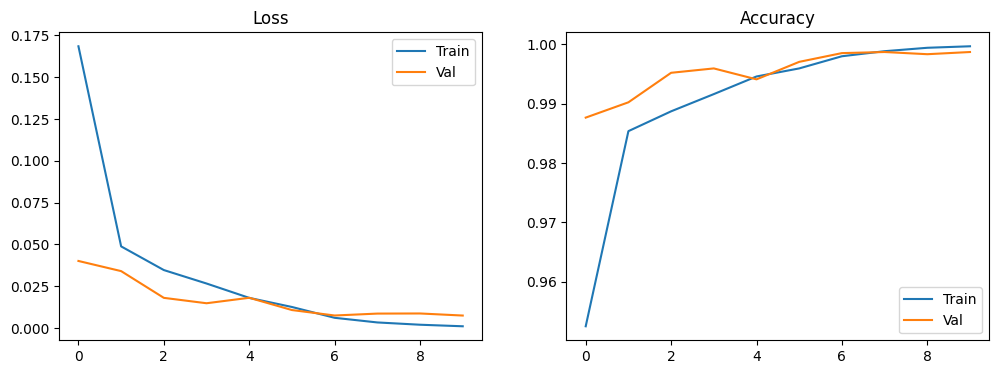

In [ ]:
# Plot training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"], label="Train")
axes[0].plot(history["val_loss"], label="Val")
axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(history["train_acc"], label="Train")
axes[1].plot(history["val_acc"], label="Val")
axes[1].set_title("Accuracy"); axes[1].legend()
plt.savefig(f"{SAVE_DIR}/training_curves.png", dpi=150, bbox_inches="tight")
plt.show()


## 8. Evaluation — Accuracy, F1, Confusion Matrix

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      1.00      1.00        72
                                 Apple___Black_rot       1.00      1.00      1.00        64
                          Apple___Cedar_apple_rust       1.00      1.00      1.00        23
                                   Apple___healthy       1.00      1.00      1.00       169
                               Blueberry___healthy       1.00      1.00      1.00       130
          Cherry_(including_sour)___Powdery_mildew       1.00      1.00      1.00       116
                 Cherry_(including_sour)___healthy       1.00      1.00      1.00        82
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.96      1.00      0.98        45
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00       113
               Corn_(maize)___Northern_Leaf_Blight       1.00      0.98      0.

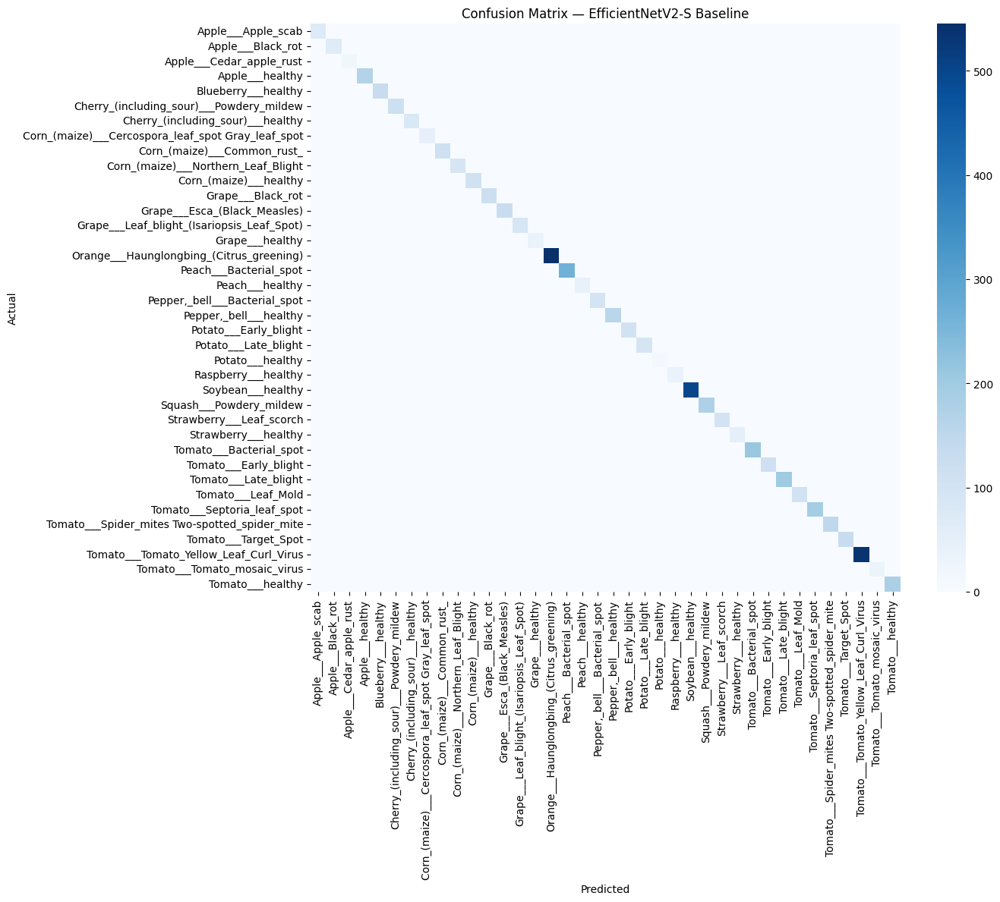

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

report_text = classification_report(all_labels, all_preds, target_names=class_names, zero_division=0)
print(report_text)

with open(f"{SAVE_DIR}/classification_report.txt", "w") as f:
    f.write(report_text)

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=False, cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=90); plt.yticks(rotation=0)
plt.title("Confusion Matrix — EfficientNetV2-S Baseline")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/confusion_matrix.png", dpi=150)
plt.show()

## 9. Explainability — Grad-CAM++

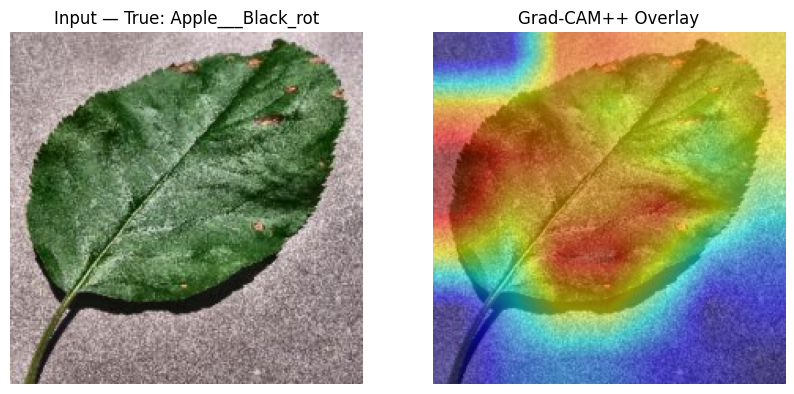

In [ ]:
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# For timm EfficientNetV2, target the last conv block
target_layers = [model.conv_head]

def visualize_gradcam(img_tensor, true_label_idx, save_name="gradcam_example.png"):
    input_tensor = img_tensor.unsqueeze(0).to(device)
    cam = GradCAMPlusPlus(model=model, target_layers=target_layers)
    targets = [ClassifierOutputTarget(true_label_idx)]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img_np = img_tensor.permute(1, 2, 0).cpu().numpy()
    img_np = std * img_np + mean
    img_np = np.clip(img_np, 0, 1)

    visualization = show_cam_on_image(img_np, grayscale_cam, use_rgb=True)

    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(img_np); ax[0].set_title(f"Input — True: {class_names[true_label_idx]}"); ax[0].axis("off")
    ax[1].imshow(visualization); ax[1].set_title("Grad-CAM++ Overlay"); ax[1].axis("off")

    plt.savefig(f"{SAVE_DIR}/{save_name}", dpi=150, bbox_inches="tight")
    plt.show()

# Test on one sample
sample_img, sample_label = test_ds[0]
visualize_gradcam(sample_img, sample_label)


### Gallery — a few more classes, for your report

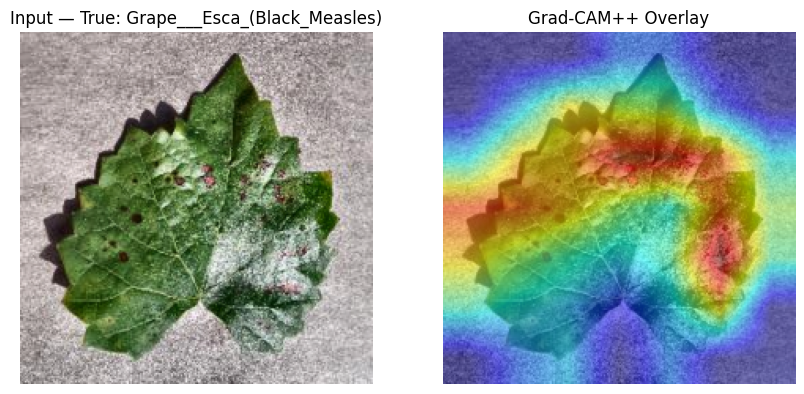

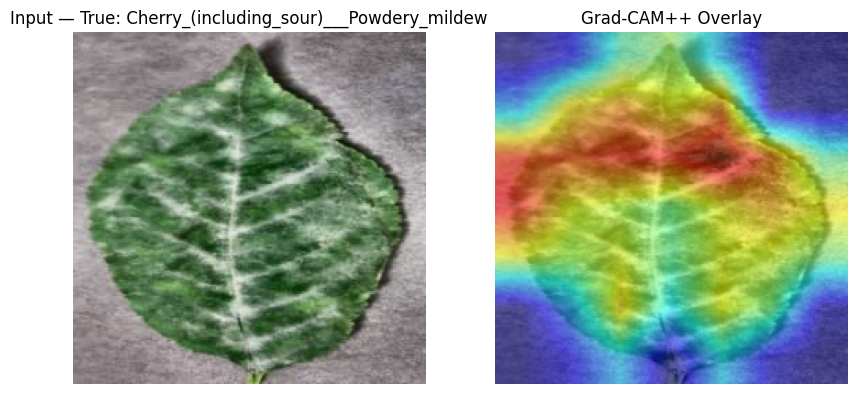

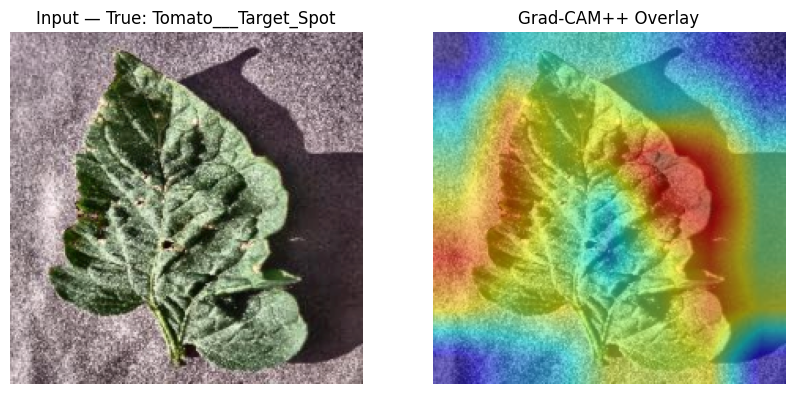

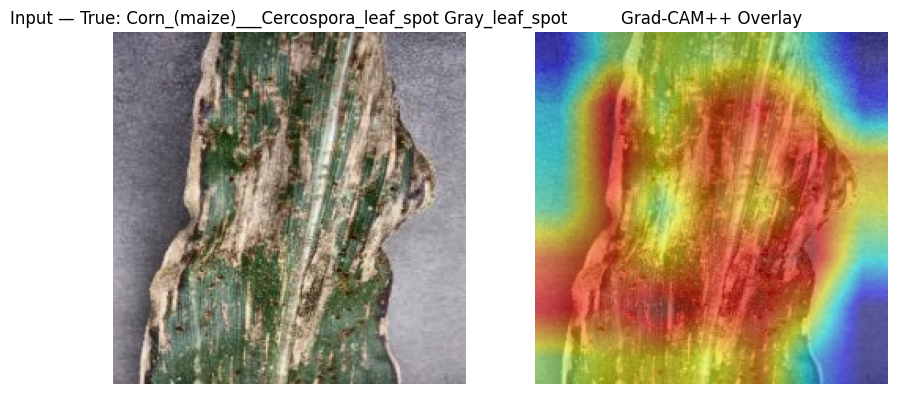

In [ ]:
import random

seen_classes = set()
samples_to_show = []
indices = list(range(len(test_ds)))
random.shuffle(indices)

for idx in indices:
    img, label = test_ds[idx]
    if label not in seen_classes:
        samples_to_show.append((img, label))
        seen_classes.add(label)
    if len(samples_to_show) == 4:
        break

for i, (img, label) in enumerate(samples_to_show):
    visualize_gradcam(img, label, save_name=f"gradcam_example_{i+1}.png")


In [ ]:
expected_files = [
    "class_names.json",
    "efficientnetv2_baseline.pth",
    "training_history.json",
    "training_curves.png",
    "classification_report.txt",
    "confusion_matrix.png",
    "gradcam_example.png",
    "gradcam_example_1.png",
    "gradcam_example_2.png",
    "gradcam_example_3.png",
    "gradcam_example_4.png",
]

present = os.listdir(SAVE_DIR)
print("Files in Drive save folder:")
for f in expected_files:
    status = "OK" if f in present else "MISSING"
    print(f"  [{status}] {f}")


Files in Drive save folder:
  [OK] class_names.json
  [OK] efficientnetv2_baseline.pth
  [OK] training_history.json
  [OK] training_curves.png
  [OK] classification_report.txt
  [OK] confusion_matrix.png
  [OK] gradcam_example.png
  [OK] gradcam_example_1.png
  [OK] gradcam_example_2.png
  [OK] gradcam_example_3.png
  [OK] gradcam_example_4.png


In [ ]:
!pip install -q timm grad-cam kaggle torchmetrics

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision.transforms as T
from torchvision.datasets import ImageFolder
import timm
import numpy as np
import cv2
import os
import json
from types import MethodType
from pathlib import Path
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 25.9 MB/s eta 0:00:00
Using device: cuda


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/plant_leaf_project'
os.makedirs(SAVE_DIR, exist_ok=True)
print("Artifacts will be saved to:", SAVE_DIR)

# Sanity check: confirm your Phase 3 baseline is actually there before continuing
baseline_files = ["efficientnetv2_baseline.pth", "classification_report.txt", "class_names.json"]
for f in baseline_files:
    path = f"{SAVE_DIR}/{f}"
    print(f"  [{'OK' if os.path.exists(path) else 'MISSING'}] {f}")

DATA_DIR = "/content/data"
if not os.path.exists(f"{DATA_DIR}/plantvillage dataset"):
    from google.colab import files
    print("Upload your kaggle.json (from https://www.kaggle.com/settings/account)")
    uploaded = files.upload()
    !mkdir -p ~/.kaggle
    !cp kaggle.json ~/.kaggle/
    !chmod 600 ~/.kaggle/kaggle.json
    !kaggle datasets download -d abdallahalidev/plantvillage-dataset -p {DATA_DIR} --unzip
else:
    print("Dataset already present in this session, skipping download.")

DATA_ROOT = f"{DATA_DIR}/plantvillage dataset/color"

Mounted at /content/drive
Artifacts will be saved to: /content/drive/MyDrive/plant_leaf_project
  [OK] efficientnetv2_baseline.pth
  [OK] classification_report.txt
  [OK] class_names.json
Upload your kaggle.json (from https://www.kaggle.com/settings/account)


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:14<00:00, 153MB/s]



In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

def apply_clahe(img):
    img_np = np.array(img)
    lab = cv2.cvtColor(img_np, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_enhanced = clahe.apply(l)
    lab_enhanced = cv2.merge((l_enhanced, a, b))
    return cv2.cvtColor(lab_enhanced, cv2.COLOR_LAB2RGB)

class CLAHETransform:
    def __call__(self, img):
        return T.functional.to_pil_image(apply_clahe(img))

train_transform = T.Compose([
    CLAHETransform(),
    T.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
val_transform = T.Compose([
    CLAHETransform(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

full_dataset_train = ImageFolder(DATA_ROOT, transform=train_transform)
full_dataset_eval = ImageFolder(DATA_ROOT, transform=val_transform)
class_names = full_dataset_train.classes
num_classes = len(class_names)

n = len(full_dataset_train)
generator = torch.Generator().manual_seed(42)   # SAME seed as Phase 3 -> same split
perm = torch.randperm(n, generator=generator).tolist()

train_n = int(0.8 * n)
val_n = int(0.1 * n)
train_idx = perm[:train_n]
val_idx = perm[train_n:train_n + val_n]
test_idx = perm[train_n + val_n:]

train_ds = Subset(full_dataset_train, train_idx)
val_ds = Subset(full_dataset_eval, val_idx)
test_ds = Subset(full_dataset_eval, test_idx)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Found {n} images, {num_classes} classes")
print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

Found 54305 images, 38 classes
Train: 43444 | Val: 5430 | Test: 5431


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * imgs.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

def validate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * imgs.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return running_loss / total, correct / total

def train_with_resume(model, optimizer, scheduler, criterion, ckpt_path, history_path, epochs=10, label=""):
    start_epoch = 0
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    if os.path.exists(ckpt_path) and os.path.exists(history_path):
        model.load_state_dict(torch.load(ckpt_path, map_location=device))
        with open(history_path) as f:
            history = json.load(f)
        start_epoch = len(history["train_loss"])
        print(f"[{label}] Found existing checkpoint — resuming from epoch {start_epoch + 1}/{epochs}")
    else:
        print(f"[{label}] No existing checkpoint — starting fresh.")

    for epoch in range(start_epoch, epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = validate(model, val_loader, criterion)
        scheduler.step()

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"[{label}] Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

        torch.save(model.state_dict(), ckpt_path)
        with open(history_path, "w") as f:
            json.dump(history, f)

    print(f"[{label}] Training complete.")
    return history

def evaluate_and_save(model, loader, class_names, report_path, cm_path, title):
    from sklearn.metrics import classification_report, confusion_matrix
    import seaborn as sns

    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            outputs = model(imgs)
            preds = outputs.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    report_text = classification_report(all_labels, all_preds, target_names=class_names, zero_division=0)
    print(report_text)
    with open(report_path, "w") as f:
        f.write(report_text)

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(14, 12))
    sns.heatmap(cm, annot=False, cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=90); plt.yticks(rotation=0)
    plt.title(title)
    plt.tight_layout()
    plt.savefig(cm_path, dpi=150)
    plt.show()

    return all_labels, all_preds

In [ ]:
VIT_NAME = "vit_small_patch16_224"

vit_model = timm.create_model(VIT_NAME, pretrained=True, num_classes=num_classes)
vit_model = vit_model.to(device)

vit_criterion = nn.CrossEntropyLoss()
vit_optimizer = optim.AdamW(vit_model.parameters(), lr=3e-4, weight_decay=1e-4)
vit_scheduler = optim.lr_scheduler.CosineAnnealingLR(vit_optimizer, T_max=10)

print(f"Model: {VIT_NAME} | Classes: {num_classes} | Params: {sum(p.numel() for p in vit_model.parameters())/1e6:.1f}M")

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Model: vit_small_patch16_224 | Classes: 38 | Params: 21.7M


In [ ]:
VIT_CKPT = f"{SAVE_DIR}/vit_baseline.pth"
VIT_HISTORY = f"{SAVE_DIR}/vit_history.json"

vit_history = train_with_resume(
    vit_model, vit_optimizer, vit_scheduler, vit_criterion,
    VIT_CKPT, VIT_HISTORY, epochs=10, label="ViT-only"
)

[ViT-only] Found existing checkpoint — resuming from epoch 11/10
[ViT-only] Training complete.


                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.99      0.99      0.99        72
                                 Apple___Black_rot       0.96      1.00      0.98        64
                          Apple___Cedar_apple_rust       1.00      0.96      0.98        23
                                   Apple___healthy       1.00      0.95      0.97       169
                               Blueberry___healthy       0.98      1.00      0.99       130
          Cherry_(including_sour)___Powdery_mildew       0.99      1.00      1.00       116
                 Cherry_(including_sour)___healthy       1.00      1.00      1.00        82
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.95      0.89      0.92        45
                       Corn_(maize)___Common_rust_       1.00      0.99      1.00       113
               Corn_(maize)___Northern_Leaf_Blight       0.93      0.98      0.

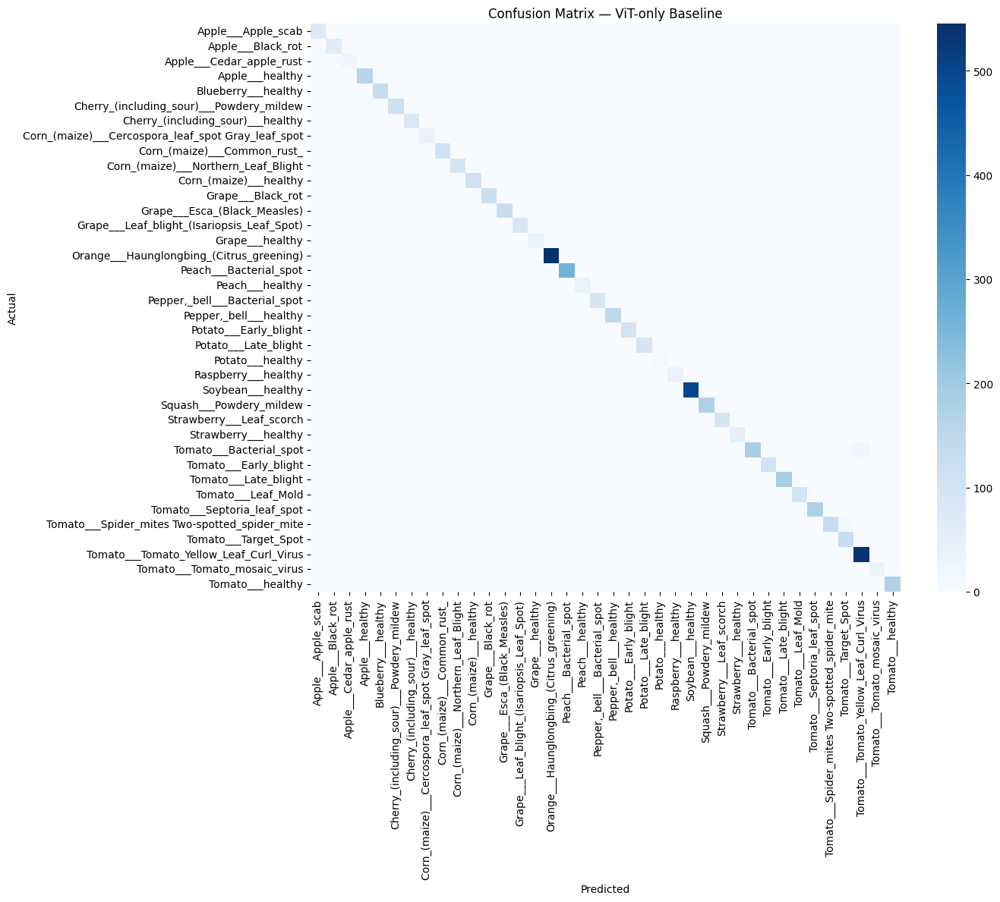

In [ ]:
vit_labels, vit_preds = evaluate_and_save(
    vit_model, test_loader, class_names,
    f"{SAVE_DIR}/vit_classification_report.txt",
    f"{SAVE_DIR}/vit_confusion_matrix.png",
    "Confusion Matrix — ViT-only Baseline"
)

In [ ]:
class HybridCNNViT(nn.Module):
    def __init__(self, cnn_name, vit_name, num_classes, dropout=0.3):
        super().__init__()
        self.cnn = timm.create_model(cnn_name, pretrained=True, num_classes=0, global_pool="avg")
        self.vit = timm.create_model(vit_name, pretrained=True, num_classes=0, global_pool="avg")

        cnn_feat_dim = self.cnn.num_features
        vit_feat_dim = self.vit.num_features

        self.fusion = nn.Sequential(
            nn.Linear(cnn_feat_dim + vit_feat_dim, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
        )
        self.classifier = nn.Linear(512, num_classes)

    def forward(self, x):
        cnn_feat = self.cnn(x)   # [B, cnn_feat_dim] — local texture features
        vit_feat = self.vit(x)   # [B, vit_feat_dim]  — global structural features
        fused = torch.cat([cnn_feat, vit_feat], dim=1)
        fused = self.fusion(fused)
        return self.classifier(fused)

CNN_NAME = "tf_efficientnetv2_s"   # same backbone as your Phase 3 baseline

hybrid_model = HybridCNNViT(CNN_NAME, VIT_NAME, num_classes).to(device)

hybrid_criterion = nn.CrossEntropyLoss()
hybrid_optimizer = optim.AdamW(hybrid_model.parameters(), lr=2e-4, weight_decay=1e-4)
hybrid_scheduler = optim.lr_scheduler.CosineAnnealingLR(hybrid_optimizer, T_max=10)

n_params = sum(p.numel() for p in hybrid_model.parameters()) / 1e6
print(f"Hybrid model: {CNN_NAME} + {VIT_NAME} | Classes: {num_classes} | Params: {n_params:.1f}M")

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

Hybrid model: tf_efficientnetv2_s + vit_small_patch16_224 | Classes: 38 | Params: 42.7M


In [ ]:
HYBRID_CKPT = f"{SAVE_DIR}/hybrid_model.pth"
HYBRID_HISTORY = f"{SAVE_DIR}/hybrid_history.json"

hybrid_history = train_with_resume(
    hybrid_model, hybrid_optimizer, hybrid_scheduler, hybrid_criterion,
    HYBRID_CKPT, HYBRID_HISTORY, epochs=10, label="Hybrid"
)

[Hybrid] Found existing checkpoint — resuming from epoch 11/10
[Hybrid] Training complete.


                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      1.00      1.00        72
                                 Apple___Black_rot       1.00      1.00      1.00        64
                          Apple___Cedar_apple_rust       1.00      1.00      1.00        23
                                   Apple___healthy       1.00      1.00      1.00       169
                               Blueberry___healthy       1.00      1.00      1.00       130
          Cherry_(including_sour)___Powdery_mildew       1.00      1.00      1.00       116
                 Cherry_(including_sour)___healthy       1.00      1.00      1.00        82
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       1.00      0.96      0.98        45
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00       113
               Corn_(maize)___Northern_Leaf_Blight       0.98      1.00      0.

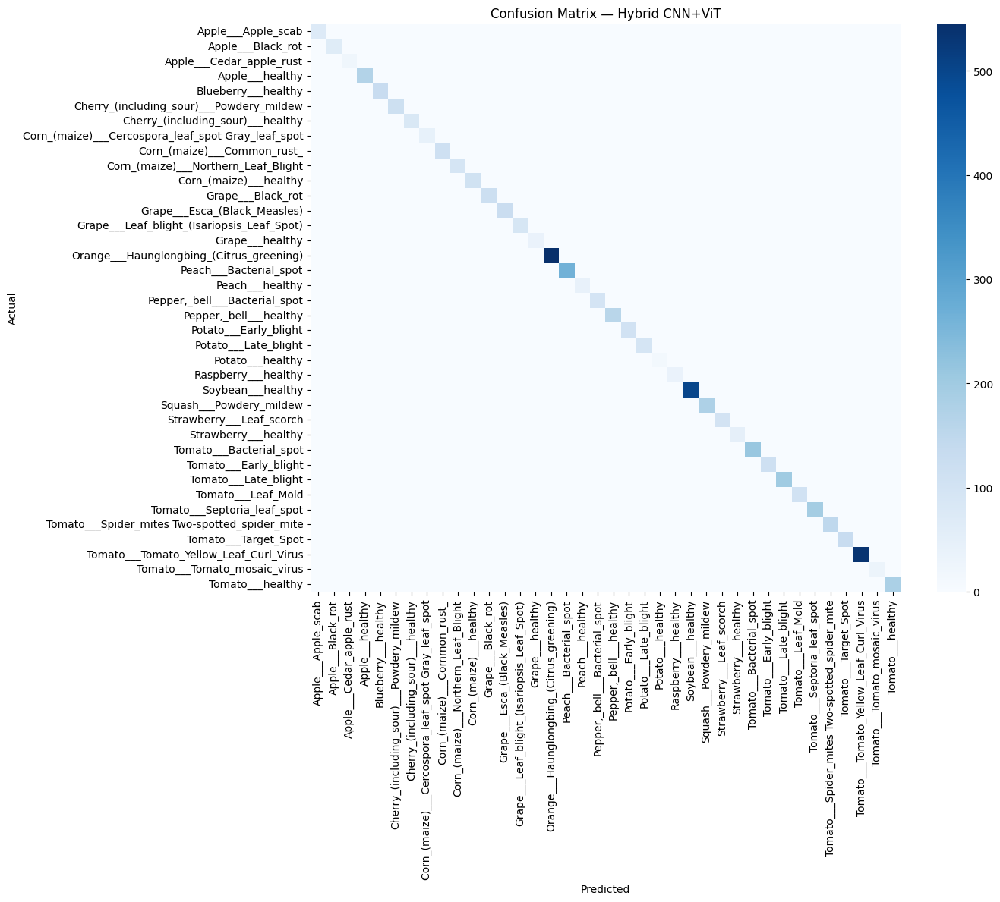

In [ ]:
hybrid_labels, hybrid_preds = evaluate_and_save(
    hybrid_model, test_loader, class_names,
    f"{SAVE_DIR}/hybrid_classification_report.txt",
    f"{SAVE_DIR}/hybrid_confusion_matrix.png",
    "Confusion Matrix — Hybrid CNN+ViT"
)

In [ ]:
import re

def parse_report(path):
    with open(path) as f:
        text = f.read()
    acc_match = re.search(r"accuracy\s+([\d.]+)", text)
    f1_match = re.search(r"macro avg\s+[\d.]+\s+[\d.]+\s+([\d.]+)", text)
    accuracy = float(acc_match.group(1)) if acc_match else None
    macro_f1 = float(f1_match.group(1)) if f1_match else None
    return accuracy, macro_f1

rows = []
paths = {
    "CNN-only (EfficientNetV2-S)": f"{SAVE_DIR}/classification_report.txt",
    "ViT-only": f"{SAVE_DIR}/vit_classification_report.txt",
    "Hybrid CNN+ViT": f"{SAVE_DIR}/hybrid_classification_report.txt",
}

print(f"{'Model':<32}{'Accuracy':>10}{'Macro F1':>10}")
print("-" * 52)
for name, path in paths.items():
    if os.path.exists(path):
        acc, f1 = parse_report(path)
        rows.append((name, acc, f1))
        print(f"{name:<32}{acc:>10.4f}{f1:>10.4f}")
    else:
        print(f"{name:<32}{'MISSING':>10}{'':>10}")

with open(f"{SAVE_DIR}/ablation_comparison.txt", "w") as f:
    f.write(f"{'Model':<32}{'Accuracy':>10}{'Macro F1':>10}\n")
    f.write("-" * 52 + "\n")
    for name, acc, f1 in rows:
        f.write(f"{name:<32}{acc:>10.4f}{f1:>10.4f}\n")

print(f"\nSaved to {SAVE_DIR}/ablation_comparison.txt")

Model                             Accuracy  Macro F1
----------------------------------------------------
CNN-only (EfficientNetV2-S)         1.0000    1.0000
ViT-only                            0.9700    0.9700
Hybrid CNN+ViT                      1.0000    1.0000

Saved to /content/drive/MyDrive/plant_leaf_project/ablation_comparison.txt


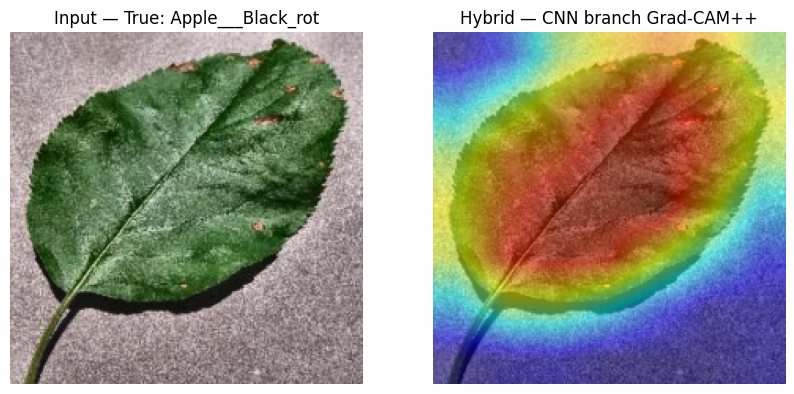

In [ ]:
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Grad-CAM needs a model whose forward returns class logits directly.
# We wrap the hybrid model's CNN branch + fusion + classifier so Grad-CAM sees a normal classifier,
# using the ViT branch's output for this specific input held fixed (detached) as context.
class HybridCNNBranchForCAM(nn.Module):
    def __init__(self, hybrid_model, vit_feat_fixed):
        super().__init__()
        self.hybrid_model = hybrid_model
        self.vit_feat_fixed = vit_feat_fixed
    def forward(self, x):
        cnn_feat = self.hybrid_model.cnn(x)
        fused = torch.cat([cnn_feat, self.vit_feat_fixed], dim=1)
        fused = self.hybrid_model.fusion(fused)
        return self.hybrid_model.classifier(fused)

def gradcam_on_hybrid(img_tensor, true_label_idx, save_name):
    input_tensor = img_tensor.unsqueeze(0).to(device)
    with torch.no_grad():
        vit_feat_fixed = hybrid_model.vit(input_tensor)  # hold ViT branch output fixed for this CAM pass

    cam_wrapper = HybridCNNBranchForCAM(hybrid_model, vit_feat_fixed).to(device)
    target_layers = [hybrid_model.cnn.conv_head]

    cam = GradCAMPlusPlus(model=cam_wrapper, target_layers=target_layers)
    targets = [ClassifierOutputTarget(true_label_idx)]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

    mean = np.array([0.485, 0.456, 0.406]); std = np.array([0.229, 0.224, 0.225])
    img_np = img_tensor.permute(1, 2, 0).cpu().numpy()
    img_np = np.clip(std * img_np + mean, 0, 1)
    visualization = show_cam_on_image(img_np, grayscale_cam, use_rgb=True)

    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(img_np); ax[0].set_title(f"Input — True: {class_names[true_label_idx]}"); ax[0].axis("off")
    ax[1].imshow(visualization); ax[1].set_title("Hybrid — CNN branch Grad-CAM++"); ax[1].axis("off")
    plt.savefig(f"{SAVE_DIR}/{save_name}", dpi=150, bbox_inches="tight")
    plt.show()

sample_img, sample_label = test_ds[0]
gradcam_on_hybrid(sample_img, sample_label, "hybrid_gradcam_cnn_branch.png")

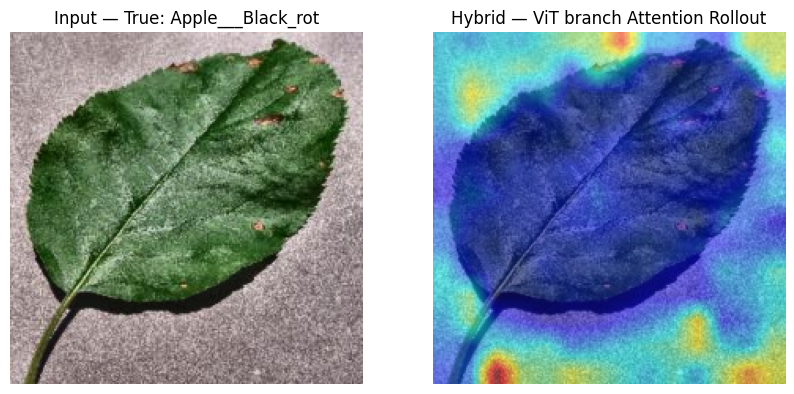

In [ ]:
def patch_vit_to_store_attention(vit_model):
    def attn_forward(self, x, attn_mask=None, **kwargs):
        B, N, C = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, C // self.num_heads).permute(2, 0, 3, 1, 4)
        q, k, v = qkv.unbind(0)
        if hasattr(self, "q_norm"):
            q, k = self.q_norm(q), self.k_norm(k)
        attn = (q @ k.transpose(-2, -1)) * self.scale
        if attn_mask is not None:
            attn = attn + attn_mask
        attn = attn.softmax(dim=-1)
        self.stored_attn = attn.detach()
        attn = self.attn_drop(attn)
        x = (attn @ v).transpose(1, 2).reshape(B, N, C)
        x = self.proj(x)
        x = self.proj_drop(x)
        return x

    for blk in vit_model.blocks:
        blk.attn.forward = MethodType(attn_forward, blk.attn)

patch_vit_to_store_attention(hybrid_model.vit)

def attention_rollout(vit_model, input_tensor):
    with torch.no_grad():
        _ = vit_model(input_tensor)

    attn_matrices = [blk.attn.stored_attn.mean(dim=1)[0] for blk in vit_model.blocks]  # avg heads, batch 0

    result = torch.eye(attn_matrices[0].size(-1)).to(device)
    for attn in attn_matrices:
        attn = attn + torch.eye(attn.size(-1)).to(device)
        attn = attn / attn.sum(dim=-1, keepdim=True)
        result = attn @ result

    mask = result[0, 1:]  # CLS token's attention to all patch tokens
    grid_size = int(mask.numel() ** 0.5)
    mask = mask.reshape(grid_size, grid_size).cpu().numpy()
    return mask

def visualize_attention_rollout(img_tensor, true_label_idx, save_name):
    input_tensor = img_tensor.unsqueeze(0).to(device)
    mask = attention_rollout(hybrid_model.vit, input_tensor)

    mean = np.array([0.485, 0.456, 0.406]); std = np.array([0.229, 0.224, 0.225])
    img_np = img_tensor.permute(1, 2, 0).cpu().numpy()
    img_np = np.clip(std * img_np + mean, 0, 1)

    mask_resized = cv2.resize(mask, (img_np.shape[1], img_np.shape[0]))
    mask_resized = (mask_resized - mask_resized.min()) / (mask_resized.max() - mask_resized.min() + 1e-8)
    heatmap = show_cam_on_image(img_np, mask_resized, use_rgb=True)

    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(img_np); ax[0].set_title(f"Input — True: {class_names[true_label_idx]}"); ax[0].axis("off")
    ax[1].imshow(heatmap); ax[1].set_title("Hybrid — ViT branch Attention Rollout"); ax[1].axis("off")
    plt.savefig(f"{SAVE_DIR}/{save_name}", dpi=150, bbox_inches="tight")
    plt.show()

visualize_attention_rollout(sample_img, sample_label, "hybrid_attention_rollout_vit_branch.png")

In [ ]:
expected_files = [
    "vit_baseline.pth", "vit_history.json", "vit_classification_report.txt", "vit_confusion_matrix.png",
    "hybrid_model.pth", "hybrid_history.json", "hybrid_classification_report.txt", "hybrid_confusion_matrix.png",
    "ablation_comparison.txt",
    "hybrid_gradcam_cnn_branch.png", "hybrid_attention_rollout_vit_branch.png",
]

present = os.listdir(SAVE_DIR)
print("Phase 4 files in Drive save folder:")
for f in expected_files:
    print(f"  [{'OK' if f in present else 'MISSING'}] {f}")

Phase 4 files in Drive save folder:
  [OK] vit_baseline.pth
  [OK] vit_history.json
  [OK] vit_classification_report.txt
  [OK] vit_confusion_matrix.png
  [OK] hybrid_model.pth
  [OK] hybrid_history.json
  [OK] hybrid_classification_report.txt
  [OK] hybrid_confusion_matrix.png
  [OK] ablation_comparison.txt
  [OK] hybrid_gradcam_cnn_branch.png
  [OK] hybrid_attention_rollout_vit_branch.png


# PHASE 5 — LESION DETECTION & SEVERITY ESTIMATION

Phase 5 objectives:
1. Create a lesion-level bounding-box dataset.
2. Train a YOLOv8 lesion detector.
3. Evaluate lesion detection using mAP@0.5 and mAP@0.5:0.95.
4. Estimate lesion-area severity using the leaf and lesion masks.
5. Validate severity against a hand-labeled subset using MAE.

In [ ]:
import torch
import numpy as np
import cv2
import os
import json
import shutil
import random
from pathlib import Path
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Fixes GrabCut's internal randomness so segmentation results are reproducible across reruns
cv2.setRNGSeed(42)

Using device: cuda


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/plant_leaf_project'
os.makedirs(SAVE_DIR, exist_ok=True)

for f in ["efficientnetv2_baseline.pth", "hybrid_model.pth", "class_names.json"]:
    path = f"{SAVE_DIR}/{f}"
    print(f"  [{'OK' if os.path.exists(path) else 'MISSING'}] {f}")

Mounted at /content/drive
  [OK] efficientnetv2_baseline.pth
  [OK] hybrid_model.pth
  [OK] class_names.json


In [ ]:
DATA_DIR = "/content/data"
if not os.path.exists(f"{DATA_DIR}/plantvillage dataset"):
    from google.colab import files
    print("Upload your kaggle.json (from https://www.kaggle.com/settings/account)")
    uploaded = files.upload()
    !mkdir -p ~/.kaggle
    !cp kaggle.json ~/.kaggle/
    !chmod 600 ~/.kaggle/kaggle.json
    !kaggle datasets download -d abdallahalidev/plantvillage-dataset -p {DATA_DIR} --unzip
else:
    print("Dataset already present in this session, skipping download.")

DATA_ROOT = f"{DATA_DIR}/plantvillage dataset/color"

Upload your kaggle.json (from https://www.kaggle.com/settings/account)


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:14<00:00, 152MB/s]



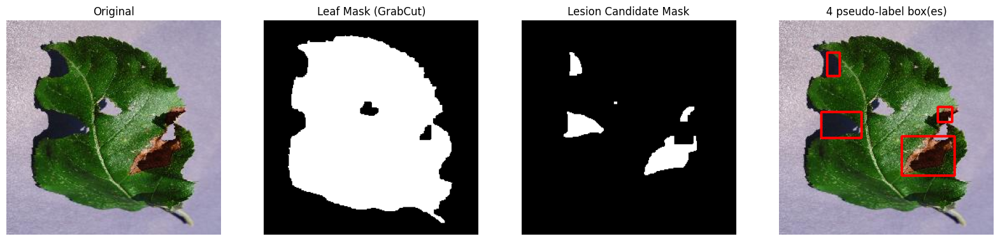

Detected 4 lesion box(es) on this sample.


In [ ]:
def segment_leaf(img_bgr):
    """Returns a binary mask (255 = leaf, 0 = background) using GrabCut."""
    h, w = img_bgr.shape[:2]
    mask = np.zeros((h, w), np.uint8)
    bgd_model = np.zeros((1, 65), np.float64)
    fgd_model = np.zeros((1, 65), np.float64)

    margin_x, margin_y = int(w * 0.05), int(h * 0.05)
    rect = (margin_x, margin_y, w - 2 * margin_x, h - 2 * margin_y)

    cv2.grabCut(img_bgr, mask, rect, bgd_model, fgd_model, 5, cv2.GC_INIT_WITH_RECT)
    binary_mask = np.where((mask == 2) | (mask == 0), 0, 255).astype("uint8")

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(binary_mask, connectivity=8)
    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        binary_mask = np.where(labels == largest_label, 255, 0).astype(np.uint8)

    kernel = np.ones((5, 5), np.uint8)
    binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel)

    return binary_mask


def find_lesion_boxes(img_bgr, min_area_fraction=0.0015, edge_erosion_px=10, max_aspect_ratio=2.5):

    leaf_mask = segment_leaf(img_bgr)
    leaf_area = np.count_nonzero(leaf_mask)
    if leaf_area == 0:
        return [], leaf_mask, np.zeros_like(leaf_mask)

    kernel_erode = np.ones((edge_erosion_px, edge_erosion_px), np.uint8)
    leaf_mask_search = cv2.erode(leaf_mask, kernel_erode)

    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    hue = hsv[:, :, 0]
    healthy_green = ((hue >= 35) & (hue <= 85)).astype(np.uint8) * 255
    lesion_candidate = cv2.bitwise_and(cv2.bitwise_not(healthy_green), leaf_mask_search)

    kernel = np.ones((3, 3), np.uint8)
    lesion_candidate = cv2.morphologyEx(lesion_candidate, cv2.MORPH_OPEN, kernel)
    lesion_candidate = cv2.morphologyEx(lesion_candidate, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(lesion_candidate, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    min_area = leaf_area * min_area_fraction
    boxes = []
    for c in contours:
        area = cv2.contourArea(c)
        if area < min_area:
            continue
        x, y, w, h = cv2.boundingRect(c)
        aspect_ratio = max(w, h) / max(min(w, h), 1)
        if aspect_ratio > max_aspect_ratio:
            continue
        boxes.append((x, y, x + w, y + h))

    return boxes, leaf_mask, lesion_candidate


# Quick visual check on one sample image
sample_cls_dir = os.path.join(DATA_ROOT, "Apple___Black_rot")
sample_file = [f for f in os.listdir(sample_cls_dir) if f.lower().endswith((".jpg", ".png"))][0]
sample_path = os.path.join(sample_cls_dir, sample_file)
img_bgr = cv2.imread(sample_path)

boxes, leaf_mask, lesion_mask = find_lesion_boxes(img_bgr)
img_with_boxes = img_bgr.copy()
for (x1, y1, x2, y2) in boxes:
    cv2.rectangle(img_with_boxes, (x1, y1), (x2, y2), (0, 0, 255), 2)

fig, ax = plt.subplots(1, 4, figsize=(20, 5))
ax[0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)); ax[0].set_title("Original"); ax[0].axis("off")
ax[1].imshow(leaf_mask, cmap="gray"); ax[1].set_title("Leaf Mask (GrabCut)"); ax[1].axis("off")
ax[2].imshow(lesion_mask, cmap="gray"); ax[2].set_title("Lesion Candidate Mask"); ax[2].axis("off")
ax[3].imshow(cv2.cvtColor(img_with_boxes, cv2.COLOR_BGR2RGB)); ax[3].set_title(f"{len(boxes)} pseudo-label box(es)"); ax[3].axis("off")
plt.savefig(f"{SAVE_DIR}/pseudo_label_example.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Detected {len(boxes)} lesion box(es) on this sample.")

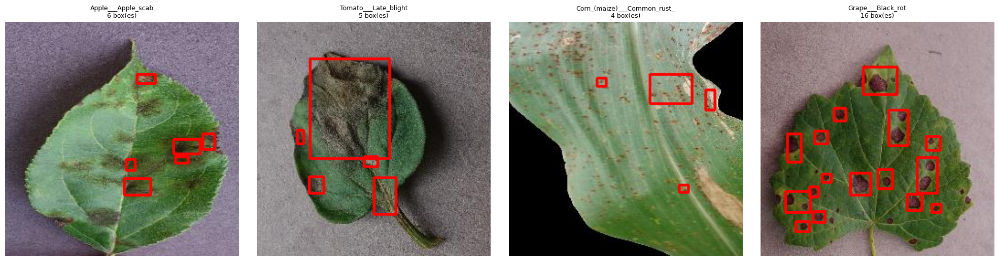

In [ ]:
check_classes = ["Apple___Apple_scab", "Tomato___Late_blight", "Corn_(maize)___Common_rust_", "Grape___Black_rot"]

fig, axes = plt.subplots(1, len(check_classes), figsize=(20, 5))
for i, cls in enumerate(check_classes):
    cls_dir = os.path.join(DATA_ROOT, cls)
    f = [x for x in os.listdir(cls_dir) if x.lower().endswith((".jpg", ".png"))][0]
    img_bgr = cv2.imread(os.path.join(cls_dir, f))
    boxes, _, _ = find_lesion_boxes(img_bgr)
    img_with_boxes = img_bgr.copy()
    for (x1, y1, x2, y2) in boxes:
        cv2.rectangle(img_with_boxes, (x1, y1), (x2, y2), (0, 0, 255), 2)
    axes[i].imshow(cv2.cvtColor(img_with_boxes, cv2.COLOR_BGR2RGB))
    axes[i].set_title(f"{cls}\n{len(boxes)} box(es)", fontsize=9)
    axes[i].axis("off")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/pseudo_label_multi_class_check.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
IMAGES_PER_CLASS = 40
SELECTED_DISEASE_CLASSES = [
    "Apple___Apple_scab",
    "Apple___Black_rot",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Septoria_leaf_spot",
    "Corn_(maize)___Common_rust_",
    "Grape___Black_rot",
    "Potato___Late_blight",
]

YOLO_DATA_DIR = "/content/lesion_dataset_pseudo"
for split in ["train", "val"]:
    os.makedirs(f"{YOLO_DATA_DIR}/images/{split}", exist_ok=True)
    os.makedirs(f"{YOLO_DATA_DIR}/labels/{split}", exist_ok=True)

random.seed(42)
total_written = 0
total_skipped_no_box = 0

for cls in SELECTED_DISEASE_CLASSES:
    cls_dir = os.path.join(DATA_ROOT, cls)
    if not os.path.isdir(cls_dir):
        print(f"  [SKIP] class folder not found: {cls}")
        continue
    files_ = [f for f in os.listdir(cls_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    random.shuffle(files_)
    selected = files_[:IMAGES_PER_CLASS]
    split_point = int(len(selected) * 0.8)

    for idx, fname in enumerate(selected):
        split = "train" if idx < split_point else "val"
        img_path = os.path.join(cls_dir, fname)
        img_bgr = cv2.imread(img_path)
        if img_bgr is None:
            continue
        h, w = img_bgr.shape[:2]

        boxes, _, _ = find_lesion_boxes(img_bgr)
        if len(boxes) == 0:
            total_skipped_no_box += 1
            continue

        stem = f"{cls}__{Path(fname).stem}"
        out_img_path = f"{YOLO_DATA_DIR}/images/{split}/{stem}.jpg"
        out_label_path = f"{YOLO_DATA_DIR}/labels/{split}/{stem}.txt"

        shutil.copy(img_path, out_img_path)

        with open(out_label_path, "w") as f:
            for (x1, y1, x2, y2) in boxes:
                cx = ((x1 + x2) / 2) / w
                cy = ((y1 + y2) / 2) / h
                bw = (x2 - x1) / w
                bh = (y2 - y1) / h
                f.write(f"0 {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}\n")

        total_written += 1

print(f"Wrote {total_written} labeled images ({total_skipped_no_box} skipped — no lesion boxes found)")

data_yaml_path = f"{YOLO_DATA_DIR}/data.yaml"
with open(data_yaml_path, "w") as f:
    f.write(f"path: {YOLO_DATA_DIR}\n")
    f.write("train: images/train\n")
    f.write("val: images/val\n")
    f.write("nc: 1\n")
    f.write("names: ['lesion']\n")

print(f"data.yaml written to {data_yaml_path}")

Wrote 300 labeled images (20 skipped — no lesion boxes found)
data.yaml written to /content/lesion_dataset_pseudo/data.yaml


In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 3.2 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

YOLO_RUN_DIR = f"{SAVE_DIR}/yolo_runs"
YOLO_RUN_NAME = "lesion_detector_pseudo"

# Always train fresh — this run takes only a few minutes, so resume logic adds more risk
# (as seen earlier, a stale/invalid checkpoint silently fell back to training on COCO instead
# of this dataset) than it saves time.
bad_run_dir = f"{YOLO_RUN_DIR}/{YOLO_RUN_NAME}"
if os.path.exists(bad_run_dir):
    shutil.rmtree(bad_run_dir)
    print("Removed old run directory — starting clean.")

assert 'data_yaml_path' in dir(), "data_yaml_path is not defined — re-run Section 4 first."
assert os.path.exists(data_yaml_path), f"data.yaml not found at {data_yaml_path} — re-run Section 4 first."

print("Training will use this data.yaml:")
with open(data_yaml_path) as f:
    print(f.read())

yolo_model = YOLO("yolov8n.pt")
train_results = yolo_model.train(
    data=data_yaml_path,
    epochs=50,
    imgsz=640,
    batch=16,
    project=YOLO_RUN_DIR,
    name=YOLO_RUN_NAME,
    patience=15,
    exist_ok=True,
)

print("YOLO training complete.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Removed old run directory — starting clean.
Training will use this data.yaml:
path: /content/lesion_dataset_pseudo
train: images/train
val: images/val
nc: 1
names: ['lesion']

Ultralytics 8.4.147 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/lesion_dataset_pseudo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, di

In [ ]:
metrics = yolo_model.val()

map50 = metrics.box.map50
map50_95 = metrics.box.map

print(f"mAP@0.5:      {map50:.4f}")
print(f"mAP@0.5:0.95: {map50_95:.4f}")

with open(f"{SAVE_DIR}/yolo_lesion_metrics.txt", "w") as f:
    f.write("NOTE: evaluated against classical-CV pseudo-labels, not human-annotated ground truth.\n")
    f.write(f"mAP@0.5:      {map50:.4f}\n")
    f.write(f"mAP@0.5:0.95: {map50_95:.4f}\n")

print(f"Saved to {SAVE_DIR}/yolo_lesion_metrics.txt")

Ultralytics 8.4.147 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 895.4±259.3 MB/s, size: 16.5 KB)
val: Scanning /content/lesion_dataset_pseudo/labels/val.cache... 64 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 64/64 24.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.7it/s 2.3s
                   all         64        308      0.659      0.608      0.676       0.46
Speed: 6.4ms preprocess, 6.2ms inference, 0.0ms loss, 3.7ms postprocess per image
Results saved to /content/runs/detect/val
mAP@0.5:      0.6756
mAP@0.5:0.95: 0.4596
Saved to /content/drive/MyDrive/plant_leaf_project/yolo_lesion_metrics.txt


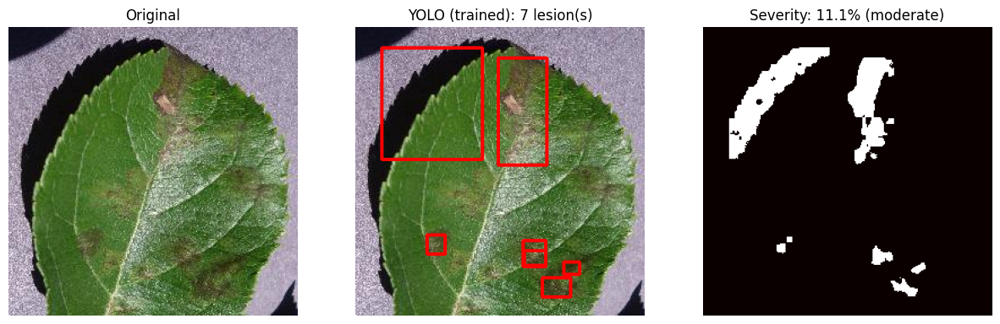

Apple___Apple_scab__1c10ab31-02b9-4008-b66f-9b44d8a9d323___FREC_Scab 3084.jpg: severity=11.1% (moderate)


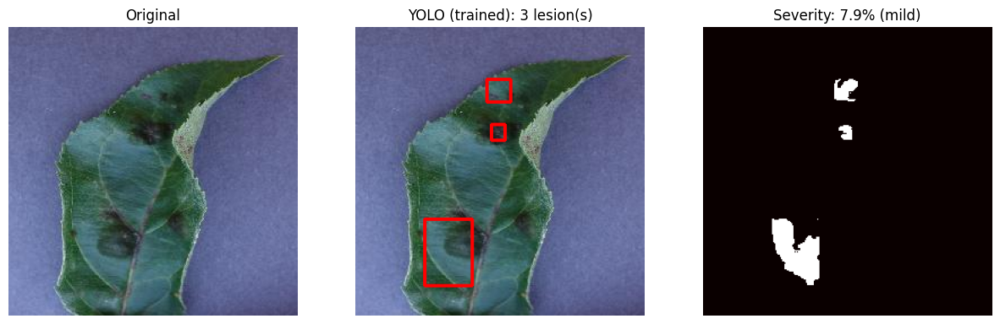

Apple___Apple_scab__48420763-bd18-49b4-9ab4-69319b5733f2___FREC_Scab 3201.jpg: severity=7.9% (mild)


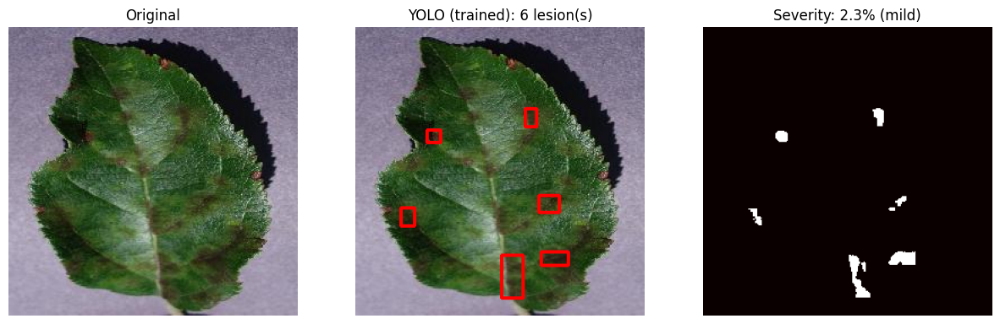

Apple___Apple_scab__8727408d-c5b9-41c4-abd7-dd8e6978efff___FREC_Scab 2995.jpg: severity=2.3% (mild)


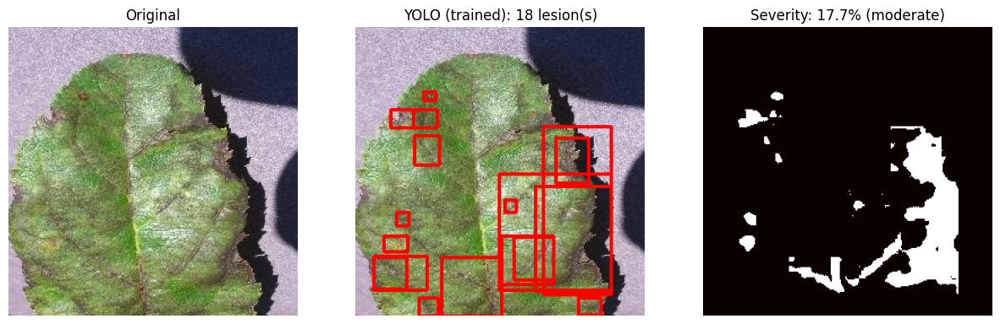

Apple___Apple_scab__8c916434-af92-4360-9833-0422aa510f7e___FREC_Scab 3245.jpg: severity=17.7% (moderate)


In [ ]:
def estimate_severity(img_bgr, boxes_xyxy):
    leaf_mask = segment_leaf(img_bgr)
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    hue = hsv[:, :, 0]
    healthy_green = ((hue >= 35) & (hue <= 85)).astype(np.uint8) * 255
    lesion_candidate = cv2.bitwise_and(cv2.bitwise_not(healthy_green), leaf_mask)

    box_mask = np.zeros_like(leaf_mask)
    for (x1, y1, x2, y2) in boxes_xyxy:
        box_mask[int(y1):int(y2), int(x1):int(x2)] = 255

    lesion_mask = cv2.bitwise_and(lesion_candidate, box_mask)

    leaf_area = np.count_nonzero(leaf_mask)
    lesion_area = np.count_nonzero(lesion_mask)
    severity_ratio = (lesion_area / leaf_area) if leaf_area > 0 else 0.0

    if severity_ratio < 0.10:
        tier = "mild"
    elif severity_ratio < 0.30:
        tier = "moderate"
    else:
        tier = "severe"

    return severity_ratio, tier, lesion_mask


def visualize_pipeline(img_path, save_name):
    img_bgr = cv2.imread(img_path)
    results = yolo_model.predict(source=img_path, conf=0.25, verbose=False)
    boxes = results[0].boxes.xyxy.cpu().numpy() if len(results[0].boxes) > 0 else np.array([])

    severity_ratio, tier, lesion_mask = estimate_severity(img_bgr, boxes)

    img_with_boxes = img_bgr.copy()
    for (x1, y1, x2, y2) in boxes:
        cv2.rectangle(img_with_boxes, (int(x1), int(y1)), (int(x2), int(y2)), (0, 0, 255), 2)

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)); ax[0].set_title("Original"); ax[0].axis("off")
    ax[1].imshow(cv2.cvtColor(img_with_boxes, cv2.COLOR_BGR2RGB)); ax[1].set_title(f"YOLO (trained): {len(boxes)} lesion(s)"); ax[1].axis("off")
    ax[2].imshow(lesion_mask, cmap="hot"); ax[2].set_title(f"Severity: {severity_ratio*100:.1f}% ({tier})"); ax[2].axis("off")
    plt.savefig(f"{SAVE_DIR}/{save_name}", dpi=150, bbox_inches="tight")
    plt.show()

    return severity_ratio, tier


demo_dir = f"{YOLO_DATA_DIR}/images/val"
demo_files = sorted(os.listdir(demo_dir))[:4]   # sorted = stable order across reruns
demo_severities = {}
for i, f in enumerate(demo_files):
    path = os.path.join(demo_dir, f)
    ratio, tier = visualize_pipeline(path, f"severity_demo_{i+1}.png")
    demo_severities[f] = ratio * 100
    print(f"{f}: severity={ratio*100:.1f}% ({tier})")

In [ ]:
print("Order to estimate in:")
for f in demo_files:
    print(" ", f)

my_estimates_percent = [12, 7, 8, 27]  # <-- fill in, matching the order printed above

if all(v is not None for v in my_estimates_percent):
    predicted = [demo_severities[f] for f in demo_files]

    mae = np.mean(np.abs(np.array(predicted) - np.array(my_estimates_percent)))
    print(f"Predicted:        {[f'{p:.1f}' for p in predicted]}")
    print(f"Manual estimates: {my_estimates_percent}")
    print(f"MAE (n={len(demo_files)}): {mae:.2f} percentage points")

    with open(f"{SAVE_DIR}/severity_manual_validation.txt", "w") as f_out:
        f_out.write(f"Files: {demo_files}\nPredicted: {predicted}\nManual: {my_estimates_percent}\nMAE: {mae:.2f}\n")
    print(f"Saved to {SAVE_DIR}/severity_manual_validation.txt")
else:
    print("Fill in my_estimates_percent above (matching the printed file order) to run this check.")

Order to estimate in:
  Apple___Apple_scab__1c10ab31-02b9-4008-b66f-9b44d8a9d323___FREC_Scab 3084.jpg
  Apple___Apple_scab__48420763-bd18-49b4-9ab4-69319b5733f2___FREC_Scab 3201.jpg
  Apple___Apple_scab__8727408d-c5b9-41c4-abd7-dd8e6978efff___FREC_Scab 2995.jpg
  Apple___Apple_scab__8c916434-af92-4360-9833-0422aa510f7e___FREC_Scab 3245.jpg
Predicted:        ['11.1', '7.9', '2.3', '17.7']
Manual estimates: [12, 7, 8, 27]
MAE (n=4): 4.20 percentage points
Saved to /content/drive/MyDrive/plant_leaf_project/severity_manual_validation.txt


In [ ]:
expected_files = [
    "pseudo_label_example.png",
    "pseudo_label_multi_class_check.png",
    "yolo_lesion_metrics.txt",
    "severity_demo_1.png", "severity_demo_2.png", "severity_demo_3.png", "severity_demo_4.png",
    "severity_manual_validation.txt",
]

present = os.listdir(SAVE_DIR)
print("Phase 5 files in Drive save folder:")
for f in expected_files:
    print(f"  [{'OK' if f in present else 'MISSING'}] {f}")

yolo_weights_path = f"{SAVE_DIR}/yolo_runs/lesion_detector_pseudo/weights/best.pt"
print(f"  [{'OK' if os.path.exists(yolo_weights_path) else 'MISSING'}] yolo_runs/lesion_detector_pseudo/weights/best.pt")

Phase 5 files in Drive save folder:
  [OK] pseudo_label_example.png
  [OK] pseudo_label_multi_class_check.png
  [OK] yolo_lesion_metrics.txt
  [OK] severity_demo_1.png
  [OK] severity_demo_2.png
  [OK] severity_demo_3.png
  [OK] severity_demo_4.png
  [OK] severity_manual_validation.txt
  [OK] yolo_runs/lesion_detector_pseudo/weights/best.pt


In [ ]:
import torch
import torch.nn as nn
import timm
import numpy as np
import cv2
import os
import json
from pathlib import Path
import matplotlib.pyplot as plt
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/plant_leaf_project'
os.makedirs(SAVE_DIR, exist_ok=True)

required = ["efficientnetv2_baseline.pth", "hybrid_model.pth", "class_names.json"]
for f in required:
    path = f"{SAVE_DIR}/{f}"
    print(f"  [{'OK' if os.path.exists(path) else 'MISSING — STOP, this phase needs it'}] {f}")

with open(f"{SAVE_DIR}/class_names.json") as f:
    class_names = json.load(f)
num_classes = len(class_names)
print(f"Loaded {num_classes} PlantVillage class names.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  [OK] efficientnetv2_baseline.pth
  [OK] hybrid_model.pth
  [OK] class_names.json
Loaded 38 PlantVillage class names.


In [ ]:
PLANTDOC_DIR = "/content/plantdoc"
if not os.path.exists(PLANTDOC_DIR):
    os.system(f"git clone -q https://github.com/pratikkayal/PlantDoc-Dataset.git {PLANTDOC_DIR}")
    print("PlantDoc cloned to", PLANTDOC_DIR)
else:
    print("PlantDoc already present in this session.")

PlantDoc cloned to /content/plantdoc


In [ ]:
# --- CNN-only baseline (Phase 3) ---
cnn_model = timm.create_model("tf_efficientnetv2_s", pretrained=False, num_classes=num_classes)
cnn_model.load_state_dict(torch.load(f"{SAVE_DIR}/efficientnetv2_baseline.pth", map_location=device))
cnn_model.to(device)
cnn_model.eval()
print("CNN-only baseline loaded.")

# --- Hybrid CNN+ViT (Phase 4) ---
class HybridCNNViT(nn.Module):
    def __init__(self, cnn_name, vit_name, num_classes, dropout=0.3):
        super().__init__()
        self.cnn = timm.create_model(cnn_name, pretrained=False, num_classes=0, global_pool="avg")
        self.vit = timm.create_model(vit_name, pretrained=False, num_classes=0, global_pool="avg")
        cnn_feat_dim = self.cnn.num_features
        vit_feat_dim = self.vit.num_features
        self.fusion = nn.Sequential(
            nn.Linear(cnn_feat_dim + vit_feat_dim, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
        )
        self.classifier = nn.Linear(512, num_classes)

    def forward(self, x):
        cnn_feat = self.cnn(x)
        vit_feat = self.vit(x)
        fused = torch.cat([cnn_feat, vit_feat], dim=1)
        fused = self.fusion(fused)
        return self.classifier(fused)

hybrid_model = HybridCNNViT("tf_efficientnetv2_s", "vit_small_patch16_224", num_classes)
hybrid_model.load_state_dict(torch.load(f"{SAVE_DIR}/hybrid_model.pth", map_location=device))
hybrid_model.to(device)
hybrid_model.eval()
print("Hybrid CNN+ViT loaded.")

CNN-only baseline loaded.
Hybrid CNN+ViT loaded.


In [ ]:
plantdoc_train_dir = f"{PLANTDOC_DIR}/train"
plantdoc_test_dir = f"{PLANTDOC_DIR}/test"

actual_dir = plantdoc_test_dir if os.path.isdir(plantdoc_test_dir) else plantdoc_train_dir
plantdoc_classes = sorted(os.listdir(actual_dir))

print(f"Using PlantDoc directory: {actual_dir}")
print(f"\nPlantDoc has {len(plantdoc_classes)} folders:")
for c in plantdoc_classes:
    n_imgs = len([f for f in os.listdir(os.path.join(actual_dir, c)) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
    print(f"  {c}  ({n_imgs} images)")

print(f"\nYour PlantVillage classes ({num_classes}):")
for c in class_names:
    print(f"  {c}")

Using PlantDoc directory: /content/plantdoc/test

PlantDoc has 27 folders:
  Apple Scab Leaf  (10 images)
  Apple leaf  (9 images)
  Apple rust leaf  (10 images)
  Bell_pepper leaf  (8 images)
  Bell_pepper leaf spot  (9 images)
  Blueberry leaf  (11 images)
  Cherry leaf  (10 images)
  Corn Gray leaf spot  (4 images)
  Corn leaf blight  (12 images)
  Corn rust leaf  (10 images)
  Peach leaf  (9 images)
  Potato leaf early blight  (8 images)
  Potato leaf late blight  (8 images)
  Raspberry leaf  (7 images)
  Soyabean leaf  (8 images)
  Squash Powdery mildew leaf  (6 images)
  Strawberry leaf  (8 images)
  Tomato Early blight leaf  (9 images)
  Tomato Septoria leaf spot  (11 images)
  Tomato leaf  (8 images)
  Tomato leaf bacterial spot  (9 images)
  Tomato leaf late blight  (10 images)
  Tomato leaf mosaic virus  (10 images)
  Tomato leaf yellow virus  (6 images)
  Tomato mold leaf  (6 images)
  grape leaf  (12 images)
  grape leaf black rot  (8 images)

Your PlantVillage classes (38)

In [ ]:
CLASS_MAPPING = {
    "Apple Scab Leaf": "Apple___Apple_scab",
    "Apple leaf": "Apple___healthy",
    "Apple rust leaf": "Apple___Cedar_apple_rust",
    "Bell_pepper leaf": "Pepper,_bell___healthy",
    "Bell_pepper leaf spot": "Pepper,_bell___Bacterial_spot",
    "Blueberry leaf": "Blueberry___healthy",
    "Cherry leaf": "Cherry_(including_sour)___healthy",
    "Corn Gray leaf spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn leaf blight": "Corn_(maize)___Northern_Leaf_Blight",
    "Corn rust leaf": "Corn_(maize)___Common_rust_",
    "grape leaf": "Grape___healthy",
    "grape leaf black rot": "Grape___Black_rot",
    "Peach leaf": "Peach___healthy",
    "Potato leaf early blight": "Potato___Early_blight",
    "Potato leaf late blight": "Potato___Late_blight",
    "Raspberry leaf": "Raspberry___healthy",
    "Soyabean leaf": "Soybean___healthy",
    "Squash Powdery mildew leaf": "Squash___Powdery_mildew",
    "Strawberry leaf": "Strawberry___healthy",
    "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato leaf": "Tomato___healthy",
    "Tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "Tomato leaf late blight": "Tomato___Late_blight",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "Tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato mold leaf": "Tomato___Leaf_Mold",
    "Tomato Septoria leaf spot": "Tomato___Septoria_leaf_spot",
    "Tomato two spotted spider mites leaf": "Tomato___Spider_mites Two-spotted_spider_mite",
}

# Keep only mappings where both sides actually exist (PlantDoc folder present AND PlantVillage class present)
valid_mapping = {}
for pd_class, pv_class in CLASS_MAPPING.items():
    if pd_class in plantdoc_classes and pv_class in class_names:
        valid_mapping[pd_class] = pv_class
    else:
        reason = []
        if pd_class not in plantdoc_classes:
            reason.append("PlantDoc folder not found")
        if pv_class not in class_names:
            reason.append("PlantVillage class not found")
        print(f"  [DROPPED] {pd_class} -> {pv_class}  ({', '.join(reason)})")

print(f"\n{len(valid_mapping)} classes will be evaluated (out of {len(CLASS_MAPPING)} attempted, "
      f"{len(plantdoc_classes)} PlantDoc folders, {num_classes} PlantVillage classes).")
print("\nFinal mapping used:")
for k, v in valid_mapping.items():
    print(f"  {k}  ->  {v}")

  [DROPPED] Tomato two spotted spider mites leaf -> Tomato___Spider_mites Two-spotted_spider_mite  (PlantDoc folder not found)

27 classes will be evaluated (out of 28 attempted, 27 PlantDoc folders, 38 PlantVillage classes).

Final mapping used:
  Apple Scab Leaf  ->  Apple___Apple_scab
  Apple leaf  ->  Apple___healthy
  Apple rust leaf  ->  Apple___Cedar_apple_rust
  Bell_pepper leaf  ->  Pepper,_bell___healthy
  Bell_pepper leaf spot  ->  Pepper,_bell___Bacterial_spot
  Blueberry leaf  ->  Blueberry___healthy
  Cherry leaf  ->  Cherry_(including_sour)___healthy
  Corn Gray leaf spot  ->  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
  Corn leaf blight  ->  Corn_(maize)___Northern_Leaf_Blight
  Corn rust leaf  ->  Corn_(maize)___Common_rust_
  grape leaf  ->  Grape___healthy
  grape leaf black rot  ->  Grape___Black_rot
  Peach leaf  ->  Peach___healthy
  Potato leaf early blight  ->  Potato___Early_blight
  Potato leaf late blight  ->  Potato___Late_blight
  Raspberry leaf  ->

In [ ]:
IMG_SIZE = 224

def apply_clahe(img):
    img_np = np.array(img)
    lab = cv2.cvtColor(img_np, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_enhanced = clahe.apply(l)
    lab_enhanced = cv2.merge((l_enhanced, a, b))
    return cv2.cvtColor(lab_enhanced, cv2.COLOR_LAB2RGB)

class CLAHETransform:
    def __call__(self, img):
        return T.functional.to_pil_image(apply_clahe(img))

eval_transform = T.Compose([
    CLAHETransform(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class PlantDocDataset(Dataset):
    def __init__(self, root_dir, mapping, pv_class_names, transform):
        self.samples = []
        self.transform = transform
        self.class_to_idx = {name: i for i, name in enumerate(pv_class_names)}
        for pd_class, pv_class in mapping.items():
            cls_dir = os.path.join(root_dir, pd_class)
            label_idx = self.class_to_idx[pv_class]
            for fname in os.listdir(cls_dir):
                if fname.lower().endswith((".jpg", ".jpeg", ".png")):
                    self.samples.append((os.path.join(cls_dir, fname), label_idx))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        from PIL import Image
        img = Image.open(path).convert("RGB")
        img = self.transform(img)
        return img, label

plantdoc_ds = PlantDocDataset(actual_dir, valid_mapping, class_names, eval_transform)
plantdoc_loader = DataLoader(plantdoc_ds, batch_size=32, shuffle=False, num_workers=2)

print(f"PlantDoc evaluation set: {len(plantdoc_ds)} images across {len(valid_mapping)} mapped classes")

PlantDoc evaluation set: 236 images across 27 mapped classes


CNN-ONLY BASELINE on PlantDoc
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.00      0.00      0.00        10
                          Apple___Cedar_apple_rust       0.00      0.00      0.00        10
                                   Apple___healthy       1.00      0.11      0.20         9
                               Blueberry___healthy       0.19      0.45      0.26        11
                 Cherry_(including_sour)___healthy       0.00      0.00      0.00        10
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.13      0.50      0.21         4
                       Corn_(maize)___Common_rust_       0.45      0.50      0.48        10
               Corn_(maize)___Northern_Leaf_Blight       0.50      0.25      0.33        12
                                 Grape___Black_rot       0.25      0.12      0.17         8
                                   Grape___health

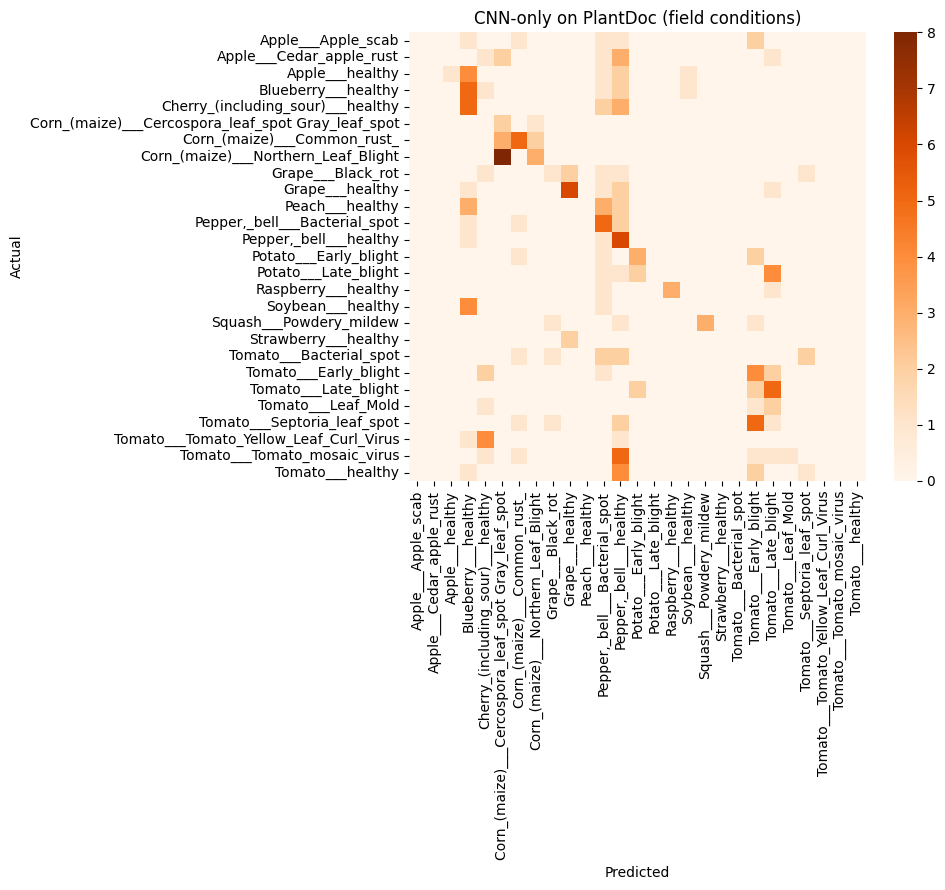

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

def evaluate_frozen(model, loader, pv_class_names, mapped_class_indices, report_path, cm_path, title):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            outputs = model(imgs)
            preds = outputs.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    mapped_names = [pv_class_names[i] for i in sorted(mapped_class_indices)]
    report_text = classification_report(
        all_labels, all_preds,
        labels=sorted(mapped_class_indices),
        target_names=mapped_names,
        zero_division=0
    )
    print(report_text)
    with open(report_path, "w") as f:
        f.write(f"NOTE: evaluated on {len(mapped_class_indices)} PlantDoc-mapped classes only, frozen model, no retraining.\n\n")
        f.write(report_text)

    cm = confusion_matrix(all_labels, all_preds, labels=sorted(mapped_class_indices))
    plt.figure(figsize=(10, 9))
    sns.heatmap(cm, annot=False, cmap="Oranges", xticklabels=mapped_names, yticklabels=mapped_names)
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=90); plt.yticks(rotation=0)
    plt.title(title)
    plt.tight_layout()
    plt.savefig(cm_path, dpi=150)
    plt.show()

    return all_labels, all_preds

mapped_class_indices = set(plantdoc_ds.class_to_idx[v] for v in valid_mapping.values())

print("=" * 60)
print("CNN-ONLY BASELINE on PlantDoc")
print("=" * 60)
cnn_pd_labels, cnn_pd_preds = evaluate_frozen(
    cnn_model, plantdoc_loader, class_names, mapped_class_indices,
    f"{SAVE_DIR}/cnn_plantdoc_report.txt", f"{SAVE_DIR}/cnn_plantdoc_confusion_matrix.png",
    "CNN-only on PlantDoc (field conditions)"
)

HYBRID CNN+ViT on PlantDoc
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      0.10      0.18        10
                          Apple___Cedar_apple_rust       0.00      0.00      0.00        10
                                   Apple___healthy       1.00      0.22      0.36         9
                               Blueberry___healthy       0.38      0.55      0.44        11
                 Cherry_(including_sour)___healthy       0.04      0.10      0.06        10
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.10      0.25      0.14         4
                       Corn_(maize)___Common_rust_       0.60      0.60      0.60        10
               Corn_(maize)___Northern_Leaf_Blight       0.80      0.33      0.47        12
                                 Grape___Black_rot       0.00      0.00      0.00         8
                                   Grape___healthy  

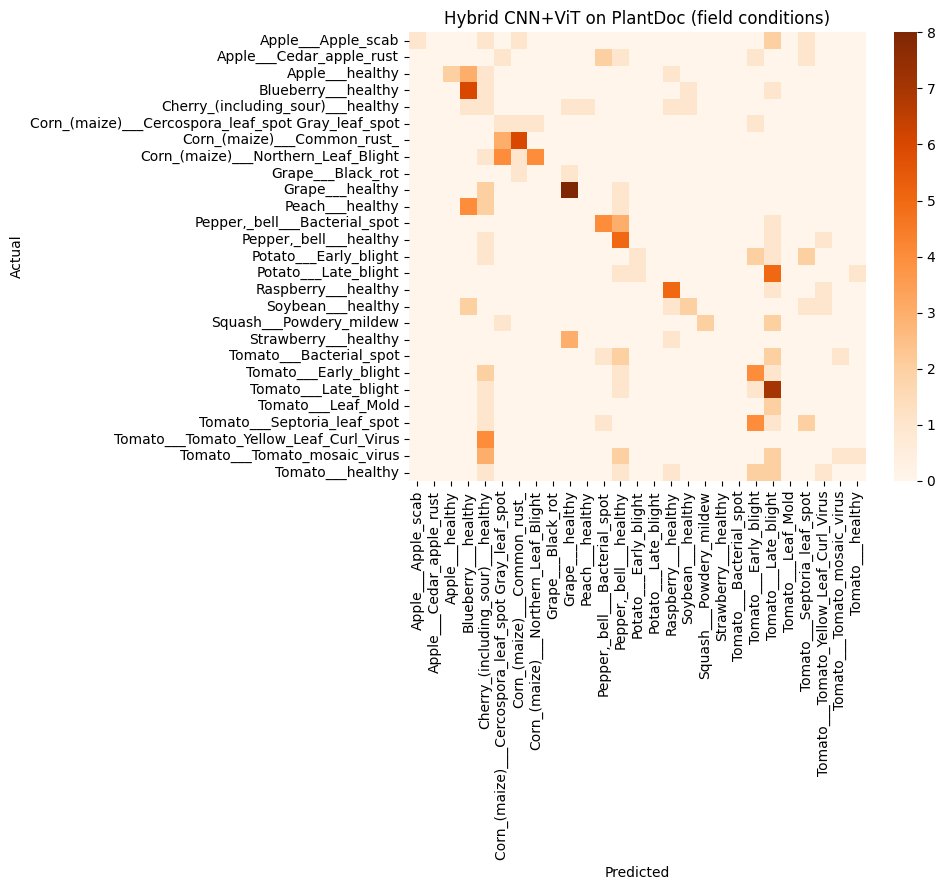

In [ ]:
print("=" * 60)
print("HYBRID CNN+ViT on PlantDoc")
print("=" * 60)
hybrid_pd_labels, hybrid_pd_preds = evaluate_frozen(
    hybrid_model, plantdoc_loader, class_names, mapped_class_indices,
    f"{SAVE_DIR}/hybrid_plantdoc_report.txt", f"{SAVE_DIR}/hybrid_plantdoc_confusion_matrix.png",
    "Hybrid CNN+ViT on PlantDoc (field conditions)"
)

In [ ]:
import re
from sklearn.metrics import accuracy_score

def parse_accuracy(path):
    with open(path) as f:
        text = f.read()
    m = re.search(r"accuracy\s+([\d.]+)", text)
    return float(m.group(1)) if m else None

# PlantVillage numbers still come from the existing saved reports (these worked fine before)
pv_cnn_acc = parse_accuracy(f"{SAVE_DIR}/classification_report.txt")
pv_hybrid_acc = parse_accuracy(f"{SAVE_DIR}/hybrid_classification_report.txt")

# PlantDoc numbers computed directly from the label/prediction arrays in memory —
# more reliable than parsing report text, since sklearn drops the "accuracy" row
# when an explicit `labels=` subset is passed to classification_report.
pd_cnn_acc = accuracy_score(cnn_pd_labels, cnn_pd_preds)
pd_hybrid_acc = accuracy_score(hybrid_pd_labels, hybrid_pd_preds)

print(f"{'Model':<20}{'PlantVillage (lab)':>20}{'PlantDoc (field)':>20}{'Drop':>12}")
print("-" * 72)
print(f"{'CNN-only':<20}{pv_cnn_acc:>20.4f}{pd_cnn_acc:>20.4f}{(pv_cnn_acc-pd_cnn_acc):>12.4f}")
print(f"{'Hybrid CNN+ViT':<20}{pv_hybrid_acc:>20.4f}{pd_hybrid_acc:>20.4f}{(pv_hybrid_acc-pd_hybrid_acc):>12.4f}")

with open(f"{SAVE_DIR}/robustness_comparison.txt", "w") as f:
    f.write(f"Evaluated on {len(mapped_class_indices)} PlantDoc-mapped classes (out of {num_classes} total PlantVillage classes).\n\n")
    f.write(f"{'Model':<20}{'PlantVillage (lab)':>20}{'PlantDoc (field)':>20}{'Drop':>12}\n")
    f.write("-" * 72 + "\n")
    f.write(f"{'CNN-only':<20}{pv_cnn_acc:>20.4f}{pd_cnn_acc:>20.4f}{(pv_cnn_acc-pd_cnn_acc):>12.4f}\n")
    f.write(f"{'Hybrid CNN+ViT':<20}{pv_hybrid_acc:>20.4f}{pd_hybrid_acc:>20.4f}{(pv_hybrid_acc-pd_hybrid_acc):>12.4f}\n")

print(f"\nSaved to {SAVE_DIR}/robustness_comparison.txt")

Model                 PlantVillage (lab)    PlantDoc (field)        Drop
------------------------------------------------------------------------
CNN-only                          1.0000              0.2203      0.7797
Hybrid CNN+ViT                    1.0000              0.2627      0.7373

Saved to /content/drive/MyDrive/plant_leaf_project/robustness_comparison.txt


In [ ]:
expected_files = [
    "cnn_plantdoc_report.txt", "cnn_plantdoc_confusion_matrix.png",
    "hybrid_plantdoc_report.txt", "hybrid_plantdoc_confusion_matrix.png",
    "robustness_comparison.txt",
]

present = os.listdir(SAVE_DIR)
print("Phase 8 files in Drive save folder:")
for f in expected_files:
    print(f"  [{'OK' if f in present else 'MISSING'}] {f}")

Phase 8 files in Drive save folder:
  [OK] cnn_plantdoc_report.txt
  [OK] cnn_plantdoc_confusion_matrix.png
  [OK] hybrid_plantdoc_report.txt
  [OK] hybrid_plantdoc_confusion_matrix.png
  [OK] robustness_comparison.txt


In [ ]:
import torch
import torch.nn as nn
import timm
import numpy as np
import os
import json
import time
from pathlib import Path

device = torch.device("cpu")  # quantized models run on CPU — this is the realistic deployment target
print("Using device:", device)

Using device: cpu


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/plant_leaf_project'

for f in ["hybrid_model.pth", "class_names.json"]:
    path = f"{SAVE_DIR}/{f}"
    print(f"  [{'OK' if os.path.exists(path) else 'MISSING — STOP'}] {f}")

with open(f"{SAVE_DIR}/class_names.json") as f:
    class_names = json.load(f)
num_classes = len(class_names)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  [OK] hybrid_model.pth
  [OK] class_names.json


In [ ]:
DATA_DIR = "/content/data"
if not os.path.exists(f"{DATA_DIR}/plantvillage dataset"):
    from google.colab import files
    print("Upload your kaggle.json (from https://www.kaggle.com/settings/account)")
    uploaded = files.upload()
    !mkdir -p ~/.kaggle
    !cp kaggle.json ~/.kaggle/
    !chmod 600 ~/.kaggle/kaggle.json
    !kaggle datasets download -d abdallahalidev/plantvillage-dataset -p {DATA_DIR} --unzip
else:
    print("Dataset already present in this session, skipping download.")

DATA_ROOT = f"{DATA_DIR}/plantvillage dataset/color"

Dataset already present in this session, skipping download.


In [ ]:
class HybridCNNViT(nn.Module):
    def __init__(self, cnn_name, vit_name, num_classes, dropout=0.3):
        super().__init__()
        self.cnn = timm.create_model(cnn_name, pretrained=False, num_classes=0, global_pool="avg")
        self.vit = timm.create_model(vit_name, pretrained=False, num_classes=0, global_pool="avg")
        cnn_feat_dim = self.cnn.num_features
        vit_feat_dim = self.vit.num_features
        self.fusion = nn.Sequential(
            nn.Linear(cnn_feat_dim + vit_feat_dim, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
        )
        self.classifier = nn.Linear(512, num_classes)

    def forward(self, x):
        cnn_feat = self.cnn(x)
        vit_feat = self.vit(x)
        fused = torch.cat([cnn_feat, vit_feat], dim=1)
        fused = self.fusion(fused)
        return self.classifier(fused)

fp32_model = HybridCNNViT("tf_efficientnetv2_s", "vit_small_patch16_224", num_classes)
fp32_model.load_state_dict(torch.load(f"{SAVE_DIR}/hybrid_model.pth", map_location="cpu"))
fp32_model.to(device)
fp32_model.eval()
print("FP32 Hybrid model loaded.")

FP32 Hybrid model loaded.


In [ ]:
int8_model = torch.quantization.quantize_dynamic(
    fp32_model,
    {nn.Linear},   # quantize all Linear layers (ViT branch + fusion + classifier head)
    dtype=torch.qint8
)
int8_model.eval()
print("INT8 dynamic quantization applied.")

# Save both versions to Drive
FP32_PATH = f"{SAVE_DIR}/hybrid_model_fp32.pth"
INT8_PATH = f"{SAVE_DIR}/hybrid_model_int8.pth"

torch.save(fp32_model.state_dict(), FP32_PATH)
torch.save(int8_model.state_dict(), INT8_PATH)
print(f"Saved FP32 to {FP32_PATH}")
print(f"Saved INT8 to {INT8_PATH}")

/tmp/ipykernel_1010/2608963964.py:1: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  int8_model = torch.quantization.quantize_dynamic(


INT8 dynamic quantization applied.
Saved FP32 to /content/drive/MyDrive/plant_leaf_project/hybrid_model_fp32.pth
Saved INT8 to /content/drive/MyDrive/plant_leaf_project/hybrid_model_int8.pth


In [ ]:
fp32_size_mb = os.path.getsize(FP32_PATH) / (1024 * 1024)
int8_size_mb = os.path.getsize(INT8_PATH) / (1024 * 1024)
size_reduction_pct = (1 - int8_size_mb / fp32_size_mb) * 100

print(f"FP32 model size:  {fp32_size_mb:.2f} MB")
print(f"INT8 model size:  {int8_size_mb:.2f} MB")
print(f"Size reduction:   {size_reduction_pct:.1f}%")

FP32 model size:  163.86 MB
INT8 model size:  100.65 MB
Size reduction:   38.6%


In [ ]:
import cv2
import torchvision.transforms as T
from torchvision.datasets import ImageFolder
from torch.utils.data import Subset, DataLoader

IMG_SIZE = 224

def apply_clahe(img):
    img_np = np.array(img)
    lab = cv2.cvtColor(img_np, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_enhanced = clahe.apply(l)
    lab_enhanced = cv2.merge((l_enhanced, a, b))
    return cv2.cvtColor(lab_enhanced, cv2.COLOR_LAB2RGB)

class CLAHETransform:
    def __call__(self, img):
        return T.functional.to_pil_image(apply_clahe(img))

eval_transform = T.Compose([
    CLAHETransform(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

full_dataset = ImageFolder(DATA_ROOT, transform=eval_transform)

# Small, fixed random sample for benchmarking (200 images — enough for a stable latency average)
generator = torch.Generator().manual_seed(42)
n = len(full_dataset)
sample_idx = torch.randperm(n, generator=generator)[:200].tolist()
benchmark_ds = Subset(full_dataset, sample_idx)
benchmark_loader = DataLoader(benchmark_ds, batch_size=1, shuffle=False, num_workers=0)

print(f"Benchmark set: {len(benchmark_ds)} images, batch size 1 (simulating real single-image inference)")

Benchmark set: 200 images, batch size 1 (simulating real single-image inference)


In [ ]:
def benchmark_model(model, loader, label, n_warmup=5):
    model.eval()
    times = []
    correct, total = 0, 0

    with torch.no_grad():
        for i, (img, label_true) in enumerate(loader):
            img = img.to(device)
            t0 = time.perf_counter()
            output = model(img)
            t1 = time.perf_counter()

            if i >= n_warmup:  # skip first few (cold-start) for a fair steady-state average
                times.append((t1 - t0) * 1000)  # ms

            pred = output.argmax(dim=1).item()
            correct += (pred == label_true.item())
            total += 1

    avg_latency_ms = np.mean(times)
    std_latency_ms = np.std(times)
    accuracy = correct / total

    print(f"[{label}] Avg latency: {avg_latency_ms:.2f} ± {std_latency_ms:.2f} ms | "
          f"Accuracy on benchmark sample: {accuracy:.4f}")
    return avg_latency_ms, accuracy

print("Benchmarking FP32...")
fp32_latency, fp32_acc = benchmark_model(fp32_model, benchmark_loader, "FP32")

print("\nBenchmarking INT8...")
int8_latency, int8_acc = benchmark_model(int8_model, benchmark_loader, "INT8")

speedup = fp32_latency / int8_latency
print(f"\nSpeedup: {speedup:.2f}x")

Benchmarking FP32...
[FP32] Avg latency: 302.35 ± 101.36 ms | Accuracy on benchmark sample: 1.0000

Benchmarking INT8...
[INT8] Avg latency: 241.58 ± 89.91 ms | Accuracy on benchmark sample: 1.0000

Speedup: 1.25x


In [ ]:
benchmark_summary = f"""Quantization Benchmark — Hybrid CNN+ViT Model
{'='*60}
{'Metric':<30}{'FP32':>14}{'INT8':>14}
{'-'*60}
{'Model size (MB)':<30}{fp32_size_mb:>14.2f}{int8_size_mb:>14.2f}
{'Avg inference latency (ms)':<30}{fp32_latency:>14.2f}{int8_latency:>14.2f}
{'Accuracy (n=200 sample)':<30}{fp32_acc:>14.4f}{int8_acc:>14.4f}
{'-'*60}
Size reduction: {size_reduction_pct:.1f}%
Speedup: {speedup:.2f}x
Accuracy change: {(int8_acc - fp32_acc)*100:+.2f} percentage points

Note: dynamic INT8 quantization applied to Linear layers only (ViT branch, fusion layer,
classifier head). Convolutional layers (CNN branch) remain FP32 — a full conv+transformer
quantization scheme was out of scope for this project.
"""

print(benchmark_summary)

with open(f"{SAVE_DIR}/quantization_benchmark.txt", "w") as f:
    f.write(benchmark_summary)

print(f"Saved to {SAVE_DIR}/quantization_benchmark.txt")

Quantization Benchmark — Hybrid CNN+ViT Model
Metric                                  FP32          INT8
------------------------------------------------------------
Model size (MB)                       163.86        100.65
Avg inference latency (ms)            302.35        241.58
Accuracy (n=200 sample)               1.0000        1.0000
------------------------------------------------------------
Size reduction: 38.6%
Speedup: 1.25x
Accuracy change: +0.00 percentage points

Note: dynamic INT8 quantization applied to Linear layers only (ViT branch, fusion layer,
classifier head). Convolutional layers (CNN branch) remain FP32 — a full conv+transformer
quantization scheme was out of scope for this project.

Saved to /content/drive/MyDrive/plant_leaf_project/quantization_benchmark.txt


In [ ]:
expected_files = [
    "hybrid_model_fp32.pth",
    "hybrid_model_int8.pth",
    "quantization_benchmark.txt",
]

present = os.listdir(SAVE_DIR)
print("Phase 7 files in Drive save folder:")
for f in expected_files:
    print(f"  [{'OK' if f in present else 'MISSING'}] {f}")

Phase 7 files in Drive save folder:
  [OK] hybrid_model_fp32.pth
  [OK] hybrid_model_int8.pth
  [OK] quantization_benchmark.txt
